# 13 — End-to-end small alignment project

## Learning objectives

- Audit and split the real dataset, then train a tiny causal policy.
- Compare SFT baseline, DPO and ORPO with fixed evaluation prompts.
- Save/reload models and record actual metrics without claiming LLM-scale success.

This notebook runs a small CPU demonstration by default. Synthetic experiments are educational, not evidence of LLM alignment. Pretrained-model downloads and GPU training require explicit opt-in. All runtime outputs stay inside `RLHF_NOTEBOOKS/`.

**Source connection:** Actual JSONL schema/audit, DPO/ORPO source practical workflows and saved-logp cautions, notes Chapters03/05/07/10. A new reproducible educational project, not reproduced original large-model training.

[Learning order and setup](README.md).

In [1]:
from pathlib import Path
import os, sys, json, math, random, copy, re, subprocess, hashlib
# Find this collection when launched from the repository, module, or notebook directory.
candidates = [Path.cwd(), Path.cwd()/'RLHF_NOTEBOOKS', Path.cwd()/'13_rlhf_ppo_dpo_orpo/RLHF_NOTEBOOKS']
ROOT = next((p.resolve() for p in candidates if (p/'source_inspection.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from RLHF_NOTEBOOKS, its parent, or the repository root.')
RUNTIME = ROOT/'runtime'; RUNTIME.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(RUNTIME/'matplotlib')
os.environ['HF_HOME'] = str(RUNTIME/'huggingface')
os.environ['HF_DATASETS_CACHE'] = str(RUNTIME/'huggingface/datasets')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(1)
print('Python', sys.version.split()[0], 'PyTorch', torch.__version__, 'CUDA', torch.cuda.is_available())

Python 3.13.9 PyTorch 2.8.0+cpu CUDA False


## Project scope and reproducibility
This CPU project uses a random small character GRU causal LM, not a pretrained instruction model. SFT is trained first; DPO's reference is then a frozen SFT copy, while ORPO also starts from identical SFT weights without a reference in its objective. Prompt-separated train14/validation3/test3 is fixed. Vocabulary is derived from observed characters across the small file (transductive tokenizer design, not reward-label fitting); production vocabularies are fixed pretrained tokenizers.

$$
\mathcal L_{SFT}=-\mathbb E\bar\ell_w,\quad \mathcal L_{DPO}=\operatorname{softplus}(-\beta m),\quad
\mathcal L_{ORPO}=\mathcal L_{SFT}+\lambda_{OR}\operatorname{softplus}(-\Delta_{OR}).
$$
$\bar\ell_w$ mean chosen completion logp, $m$ reference-adjusted summed-logp pair margin, $\Delta_{OR}$ normalized-likelihood log odds. Full definitions/tests are repeated below so this notebook runs independently. Equal-sequence SFT averaging is an educational weighting choice; TRL averages tokens in some paths. Every measured number below comes from executed CPU code, not source saved outputs.

In [2]:
def read_preferences():
    path = ROOT.parent/'reward_preferences_dataset.jsonl'
    if path.exists():
        raw = path.read_bytes(); origin = str(path)
    else:
        # Originals are currently missing from the working tree. Read their Git blob;
        # never restore, overwrite or silently substitute invented preference records.
        gitroot = Path(subprocess.check_output(['git','rev-parse','--show-toplevel'], cwd=ROOT, text=True).strip())
        rel = (ROOT.parent/'reward_preferences_dataset.jsonl').relative_to(gitroot).as_posix()
        raw = subprocess.check_output(['git','show','HEAD:'+rel], cwd=gitroot)
        origin = 'HEAD:'+rel
    expected = json.loads((ROOT/'source_inspection.json').read_text())
    digest = next(r['sha256'] for r in expected if r['source']=='reward_preferences_dataset.jsonl')
    assert hashlib.sha256(raw).hexdigest() == digest, 'Dataset changed: re-audit before proceeding'
    rows = [json.loads(line) for line in raw.decode('utf-8').splitlines()]
    for row in rows:
        assert set(row)=={'prompt','chosen','rejected'}
        assert all(isinstance(row[k],str) and row[k].strip() for k in row)
        assert row['chosen'].strip()!=row['rejected'].strip()
    assert len({r['prompt'].strip().lower() for r in rows})==len(rows)
    print('Dataset origin:',origin,'records:',len(rows),'fields:',list(rows[0]))
    return rows
rows = read_preferences()
indices = np.random.default_rng(42).permutation(len(rows))
train_rows = [rows[i] for i in indices[:14]]
valid_rows = [rows[i] for i in indices[14:17]]
test_rows = [rows[i] for i in indices[17:]]
assert not ({r['prompt'] for r in train_rows} & {r['prompt'] for r in valid_rows+test_rows})
print('Prompt-separated split:',len(train_rows),len(valid_rows),len(test_rows))

Dataset origin: HEAD:13_rlhf_ppo_dpo_orpo/reward_preferences_dataset.jsonl records: 20 fields: ['prompt', 'chosen', 'rejected']
Prompt-separated split: 14 3 3


In [3]:
# Character vocabulary: finite encoding avoids tokenizer downloads and boundary merges.
# This is an educational tokenizer, not a pretrained chat model's tokenizer.
CHARS = sorted(set(''.join(r[k] for r in rows for k in ('prompt','chosen','rejected'))+'Question: Answer:\n'))
vocab = {'<pad>':0,'<bos>':1,'<eos>':2,'<unk>':3, **{c:i+4 for i,c in enumerate(CHARS)}}
def encode(text): return [vocab.get(c,3) for c in text]
def pair_batch(examples, side):
    seqs=[]; response=[]
    for r in examples:
        prefix=[1]+encode('Question: '+r['prompt']+'\nAnswer: ')
        answer=encode(r[side])+[2]
        seqs.append(prefix+answer);response.append([0]*len(prefix)+[1]*len(answer))
    length=max(map(len,seqs))
    ids=torch.tensor([s+[0]*(length-len(s)) for s in seqs])
    attention=ids.ne(0)
    completion=torch.tensor([m+[0]*(length-len(m)) for m in response],dtype=torch.bool)
    return ids,attention,completion

def completion_logps(logits,ids,attention,completion,average=False):
    assert logits.shape[:2]==ids.shape==attention.shape==completion.shape
    target=ids[:,1:]
    assert (target>=0).all() and (target<logits.shape[-1]).all()
    active=completion[:,1:].bool() & attention[:,1:].bool() & attention[:,:-1].bool()
    counts=active.sum(-1)
    if (counts==0).any(): raise ValueError('Empty scored completion')
    selected=F.log_softmax(logits[:,:-1].float(),-1).gather(-1,target.unsqueeze(-1)).squeeze(-1)
    total=selected.masked_fill(~active,0).sum(-1)
    return total/counts if average else total

class TinyLM(nn.Module):
    def __init__(self):
        super().__init__();self.embedding=nn.Embedding(len(vocab),24,padding_idx=0)
        self.rnn=nn.GRU(24,32,batch_first=True);self.head=nn.Linear(32,len(vocab))
    def forward(self,ids): return self.head(self.rnn(self.embedding(ids))[0])

def score(model,batch,average=False):
    ids,att,mask=batch
    return completion_logps(model(ids),ids,att,mask,average)

def finite_step(loss,model,optimizer):
    assert torch.isfinite(loss).all()
    optimizer.zero_grad();loss.backward()
    grads=[p.grad for p in model.parameters() if p.requires_grad and p.grad is not None]
    assert grads and all(torch.isfinite(g).all() for g in grads)
    assert any(g.abs().sum()>0 for g in grads), 'No gradient signal'
    nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()

# Meaningful causal-shift, prompt exclusion, padding and gradient tests.
ids=torch.tensor([[1,4,5,2,0]]); att=ids.ne(0);mask=torch.tensor([[0,0,1,1,0]],dtype=torch.bool)
logits=torch.zeros(1,5,len(vocab),requires_grad=True)
s=completion_logps(logits,ids,att,mask)
assert torch.allclose(s,torch.tensor([-2*math.log(len(vocab))]))
(-s.sum()).backward()
assert logits.grad[0,0].abs().sum()==0   # predicts masked prompt token
assert logits.grad[0,1:3].abs().sum()>0  # predicts response and EOS
assert logits.grad[0,3:].abs().sum()==0  # padding / unused last logits
assert torch.allclose(completion_logps(logits.detach(),ids,att,mask,True),s.detach()/2)
try:
    completion_logps(logits.detach(),ids,att,torch.zeros_like(mask))
    raise AssertionError('Should reject empty completions')
except ValueError: pass
print('Causal shifting, response/padding masking and gradient checks passed.')

Causal shifting, response/padding masking and gradient checks passed.


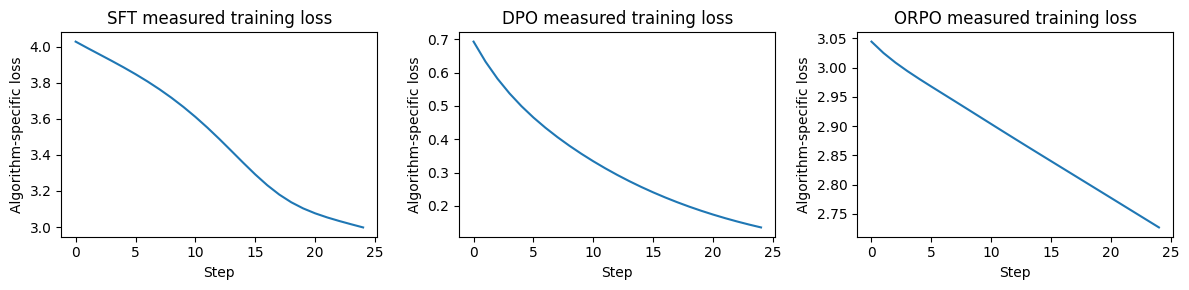

In [4]:
def dpo_objective(w,l,rw,rl,beta=.1):return F.softplus(-beta*((w-l)-(rw-rl))).mean()
def stable_log1mexp(x):
    if (x>=0).any():raise ValueError('Require negative logp')
    y=torch.empty_like(x);far=x < -math.log(2)
    y[far]=torch.log1p(-x[far].exp());y[~far]=torch.log(-torch.expm1(x[~far]));return y
def orpo_objective(w,l):return -w.mean()+.1*F.softplus(-((w-stable_log1mexp(w))-(l-stable_log1mexp(l)))).mean()
base=TinyLM();chosen=pair_batch(train_rows,'chosen');rejected=pair_batch(train_rows,'rejected')
opt=torch.optim.Adam(base.parameters(),lr=.003);curves={'SFT':[],'DPO':[],'ORPO':[]}
for step in range(25):
    loss=-score(base,chosen,True).mean();finite_step(loss,base,opt);curves['SFT'].append(loss.item())
reference=copy.deepcopy(base).eval().requires_grad_(False)
models={'SFT':copy.deepcopy(base)}
with torch.no_grad():rw=score(reference,chosen);rl=score(reference,rejected)
for name in ['DPO','ORPO']:
    model=copy.deepcopy(base);opt=torch.optim.Adam(model.parameters(),lr=.002)
    for step in range(25):
        if name=='DPO':loss=dpo_objective(score(model,chosen),score(model,rejected),rw,rl)
        else:loss=orpo_objective(score(model,chosen,True),score(model,rejected,True))
        finite_step(loss,model,opt);curves[name].append(loss.item())
    models[name]=model
assert all(p.grad is None for p in reference.parameters())
fig,axes=plt.subplots(1,3,figsize=(12,3))
for axis,(name,curve) in zip(axes,curves.items()):axis.plot(curve);axis.set(title=name+' measured training loss',xlabel='Step',ylabel='Algorithm-specific loss')
plt.tight_layout();plt.show()

In [5]:
@torch.no_grad()
def metrics(model,examples):
    model.eval();cw=pair_batch(examples,'chosen');cl=pair_batch(examples,'rejected')
    w=score(model,cw);l=score(model,cl);wm=score(model,cw,True);lm=score(model,cl,True)
    rw=score(reference,cw);rl=score(reference,cl)
    return {'sum_logp_accuracy':w.gt(l).float().mean().item(),'mean_logp_accuracy':wm.gt(lm).float().mean().item(),
            'relative_margin':((w-l)-(rw-rl)).mean().item(),'chosen_nll':(-wm).mean().item()}
validation={name:metrics(model,valid_rows) for name,model in models.items()}
print('Validation:',json.dumps(validation,indent=2))
# One final fixed test comparison; do not tune against this small test set.
test={name:metrics(model,test_rows) for name,model in models.items()}
print('Test:',json.dumps(test,indent=2))
experiment={'seed':42,'origin':'real local20-row preference file (Git fallback if missing)','train_prompts':[r['prompt'] for r in train_rows],
            'validation':validation,'test':test,'torch':torch.__version__,'model':'random character GRU24/32','steps_per_stage':25,
            'limits':['three test prompts','length confound','transductive character vocabulary','no pretrained LLM','single seed']}
project=RUNTIME/'alignment_project';project.mkdir(exist_ok=True)
(project/'metrics.json').write_text(json.dumps(experiment,indent=2))
for name,model in models.items():
    path=project/(name.lower()+'.pt');torch.save({'state':model.state_dict(),'vocab':vocab},path)
    loaded=TinyLM();loaded.load_state_dict(torch.load(path,weights_only=True)['state']);loaded.eval()
    x=pair_batch(test_rows,'chosen')[0]
    with torch.no_grad():assert torch.allclose(model(x),loaded(x))
print('All local checkpoint reloads agree. Experiment:',project)

Validation: {
  "SFT": {
    "sum_logp_accuracy": 0.0,
    "mean_logp_accuracy": 0.6666666865348816,
    "relative_margin": -1.52587890625e-05,
    "chosen_nll": 3.129448652267456
  },
  "DPO": {
    "sum_logp_accuracy": 0.0,
    "mean_logp_accuracy": 1.0,
    "relative_margin": 7.9857635498046875,
    "chosen_nll": 3.060321807861328
  },
  "ORPO": {
    "sum_logp_accuracy": 0.0,
    "mean_logp_accuracy": 0.6666666865348816,
    "relative_margin": 8.40166187286377,
    "chosen_nll": 2.8853559494018555
  }
}
Test: {
  "SFT": {
    "sum_logp_accuracy": 0.0,
    "mean_logp_accuracy": 0.6666666865348816,
    "relative_margin": -1.0172526344831567e-05,
    "chosen_nll": 3.127394914627075
  },
  "DPO": {
    "sum_logp_accuracy": 0.0,
    "mean_logp_accuracy": 0.6666666865348816,
    "relative_margin": 5.4892425537109375,
    "chosen_nll": 3.0590784549713135
  },
  "ORPO": {
    "sum_logp_accuracy": 0.0,
    "mean_logp_accuracy": 0.6666666865348816,
    "relative_margin": 5.230448246002197,
 

## Extend to actual LLM alignment

Use notebook07/11 to replace TinyLM with a compatible pretrained causal model and tokenizer; enable GPU only intentionally. Use notebook03 then05 for reward-model PPO, or notebook09 for verifiable group rewards. Keep SFT/reference roles and evaluation data fixed across comparisons, log resources, and perform instruction/task regressions. This project compares pair scoring, not human win rate or safety. No conclusion of universal superiority follows from three test pairs.

## Exercises

1. Train a vocabulary using only train rows and add an UNK policy; compare leakage implications.
2. Repeat three seeds and report variation, without tuning on test.
3. Add a held-out task-generation suite and baseline length analysis.

## Key takeaways

Recompute the worked examples, inspect masks and gradients, and evaluate independently of the training objective. A small training-loss decrease does not establish generalization or alignment. Record the model, data split, seeds and dependency versions before interpreting results.